PARTIE 1:



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

t = pd.read_csv("train.csv") 
test=pd.read_csv("test.csv")

print("Dimension du dataset:",t.shape) 
display(t.head()) 

#les variabless numeriques
numerical_columns = t.select_dtypes(include=np.number).columns
print("Variables numeriques :",numerical_columns.tolist())

#les variables categorielles
categorical_columns = t.select_dtypes(include=["str", "category", "bool"]).columns
print("Variables categorielles :",categorical_columns.tolist())

print("\n les valeurs manquantes :",t.isnull().sum()) 
print("\n le nombre de doublons :",t.duplicated().sum())

Dimension du dataset: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Variables numeriques : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Variables categorielles : ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

 les valeurs manquantes : PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

 le nombre de doublons : 0


PARTIE 2:



In [2]:
missing_percent = t.isnull().mean()*100
print("pourcentage es valeurs manquantes :\n",missing_percent)

pourcentage es valeurs manquantes :
 PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [3]:
t=t.drop(columns=["Cabin"])
test=test.drop(columns=["Cabin"])
print("la colonne cabin a été supprimée")

age_median = t["Age"].median()
print("la mediane est :",age_median)

t["Age"] = t["Age"].fillna(age_median)
test["Age"] = test["Age"].fillna(age_median)


embarked_mode = t["Embarked"].mode()[0]
print("le mode est :",embarked_mode)

t["Embarked"] = t["Embarked"].fillna(embarked_mode)
test["Embarked"] = test["Embarked"].fillna(embarked_mode)

print("les valeurs manquantes apres le traitement :\n",t.isnull().sum())

la colonne cabin a été supprimée
la mediane est : 28.0
le mode est : S
les valeurs manquantes apres le traitement :
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


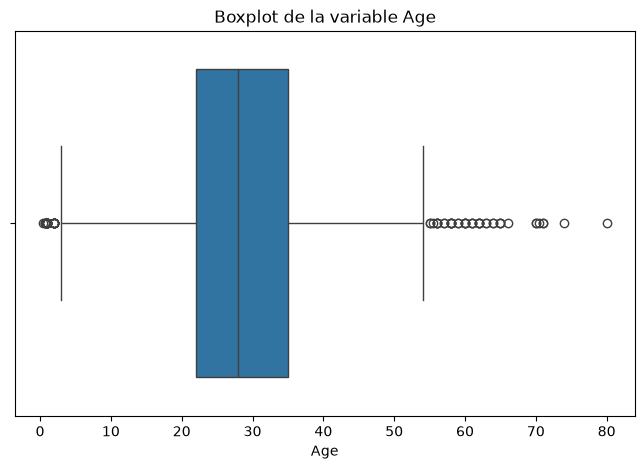

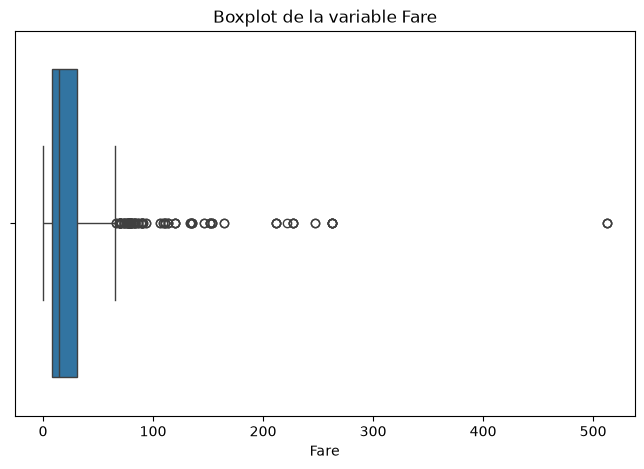

In [4]:
# boxplot de age
plt.figure(figsize=(8, 5))
sns.boxplot(x=t["Age"])

plt.title("Boxplot de la variable Age")
plt.xlabel("Age")
plt.show()

# boxplot de fare
plt.figure(figsize=(8, 5))
sns.boxplot(x=t["Fare"])

plt.title("Boxplot de la variable Fare")
plt.xlabel("Fare")
plt.show()

In [5]:
# detection  de age

Q1_age = t["Age"].quantile(0.25)
Q3_age = t["Age"].quantile(0.75)

IQR_age = Q3_age - Q1_age

lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

outliers_age = t[(t["Age"] < lower_age) | (t["Age"] > upper_age)]

print("Q1 Age :", Q1_age)
print("Q3 Age :", Q3_age)
print("IQR Age :", IQR_age)
print("Lower limit Age :", lower_age)
print("Upper limit Age :", upper_age)
print("Nombre d'Outliers Age :", len(outliers_age))

# traitement de age

age_median = t["Age"].median()

t.loc[(t["Age"] < lower_age) | (t["Age"] > upper_age),"Age"] = age_median
test.loc[(test["Age"] < lower_age) | (test["Age"] > upper_age), "Age"] = age_median 

print("Outliers age dans train après traitement :",((t["Age"] < lower_age) | (t["Age"] > upper_age)).sum())
print("Outliers age dans test après tritement :",((test["Age"] < lower_age) | (test["Age"] > upper_age)).sum())



# detection de fare

Q1_fare = t["Fare"].quantile(0.25)
Q3_fare = t["Fare"].quantile(0.75)

IQR_fare = Q3_fare - Q1_fare

lower_fare = Q1_fare - 1.5 * IQR_fare
upper_fare = Q3_fare + 1.5 * IQR_fare

outliers_fare = t[(t["Fare"] < lower_fare) | (t["Fare"] > upper_fare)]

print("\n Q1 Fare :", Q1_fare)
print("Q3 Fare :", Q3_fare)
print("IQR Fare :", IQR_fare)
print("Lower limit Fare :", lower_fare)
print("Upper limit Fare :", upper_fare)
print("Nombre d'Outliers Fare :", len(outliers_fare))


# traitement de fare

fare_median = t["Fare"].median()

t.loc[(t["Fare"] < lower_fare) | (t["Fare"] > upper_fare),"Fare"] = fare_median
test.loc[(test["Fare"] < lower_fare) | (test["Fare"] > upper_fare), "Fare"] = fare_median 


print("Outliers fare dans train après traitement :",((t["Fare"] < lower_fare) | (t["Fare"] > upper_fare)).sum())
print("Outliers fare dans test  après traitement :",((test["Fare"] < lower_fare) | (test["Fare"] > upper_fare)).sum())

Q1 Age : 22.0
Q3 Age : 35.0
IQR Age : 13.0
Lower limit Age : 2.5
Upper limit Age : 54.5
Nombre d'Outliers Age : 66
Outliers age dans train après traitement : 0
Outliers age dans test après tritement : 0

 Q1 Fare : 7.9104
Q3 Fare : 31.0
IQR Fare : 23.0896
Lower limit Fare : -26.724
Upper limit Fare : 65.6344
Nombre d'Outliers Fare : 116
Outliers fare dans train après traitement : 0
Outliers fare dans test  après traitement : 0


PARTIE 3:

In [6]:
t = pd.get_dummies( t,columns=["Sex", "Embarked"],dtype=int)
test = pd.get_dummies(test, columns=["Sex", "Embarked"], dtype=int) 

display(t.head())
display(t.columns)

print("dimensions après encodage :", t.shape)
print("dimensions après encodage :", test.shape)



,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,0,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,14.4542,1,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,1,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,1,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0,1,0,0,1


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q',
       'Embarked_S'],
      dtype='str')

dimensions après encodage : (891, 14)
dimensions après encodage : (418, 13)


In [7]:
minmax = MinMaxScaler()
c = ["Age", "Fare", "SibSp", "Parch","Pclass"]
t_minmax = t.copy()
test_minmax = test.copy()

t_minmax[c] = minmax.fit_transform(t_minmax[c]) 
test_minmax[c] = minmax.transform(test[c]) 

display("avant :",t[c].head())
display("apres :",t_minmax[c].head())  

print(t_minmax[c].min())
print(t_minmax[c].max())


'avant :'

,Age,Fare,SibSp,Parch,Pclass
0,22.0,7.2500,1,0,3
1,38.0,14.4542,1,0,1
2,26.0,7.9250,0,0,3
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,3


'apres :'

,Age,Fare,SibSp,Parch,Pclass
0,0.372549,0.111538,0.125,0.0,1.0
1,0.686275,0.222372,0.125,0.0,0.0
2,0.450980,0.121923,0.000,0.0,1.0
3,0.627451,0.816923,0.125,0.0,0.0
4,0.627451,0.123846,0.000,0.0,1.0


Age       0.0
Fare      0.0
SibSp     0.0
Parch     0.0
Pclass    0.0
dtype: float64
Age       1.0
Fare      1.0
SibSp     1.0
Parch     1.0
Pclass    1.0
dtype: float64


In [8]:
standard = StandardScaler()

t_standard = t.copy()
test_standard = test.copy()

t_standard[c] = standard.fit_transform(t[c])
test_standard[c] = standard.transform(test[c])

display("avant :",t[c].head())
display("apres :",t_standard[c].head())

'avant :'

,Age,Fare,SibSp,Parch,Pclass
0,22.0,7.2500,1,0,3
1,38.0,14.4542,1,0,1
2,26.0,7.9250,0,0,3
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,3


'apres :'

,Age,Fare,SibSp,Parch,Pclass
0,-0.661724,-0.797554,0.432793,-0.473674,0.827377
1,0.972921,-0.230556,0.432793,-0.473674,-1.566107
2,-0.253063,-0.744429,-0.474545,-0.473674,0.827377
3,0.666425,2.811012,0.432793,-0.473674,-1.566107
4,0.666425,-0.734591,-0.474545,-0.473674,0.827377


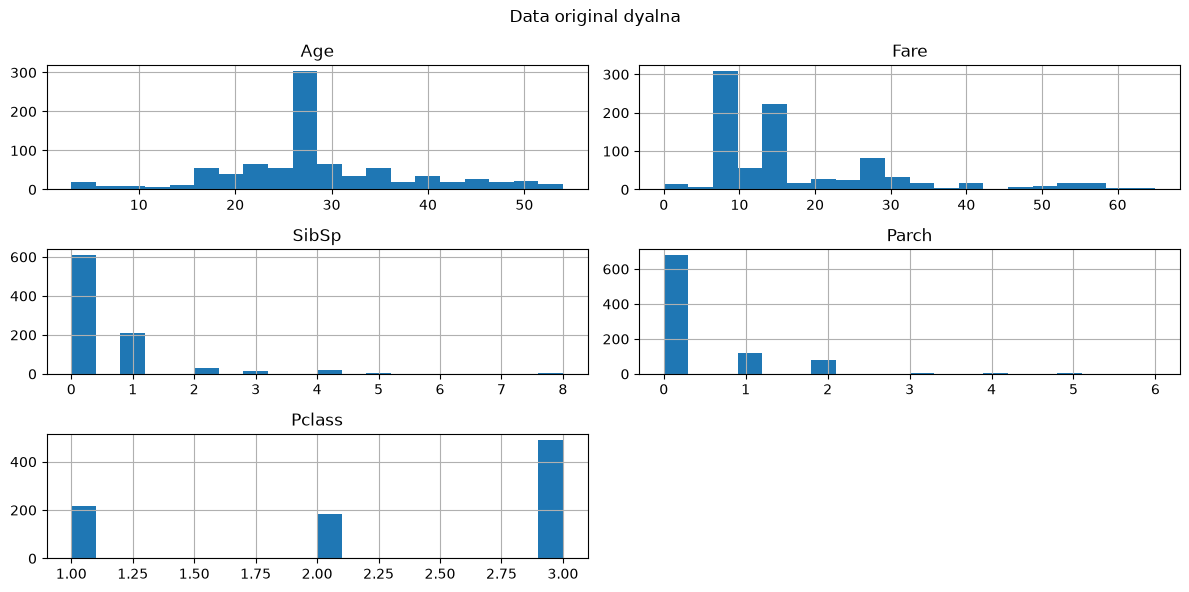

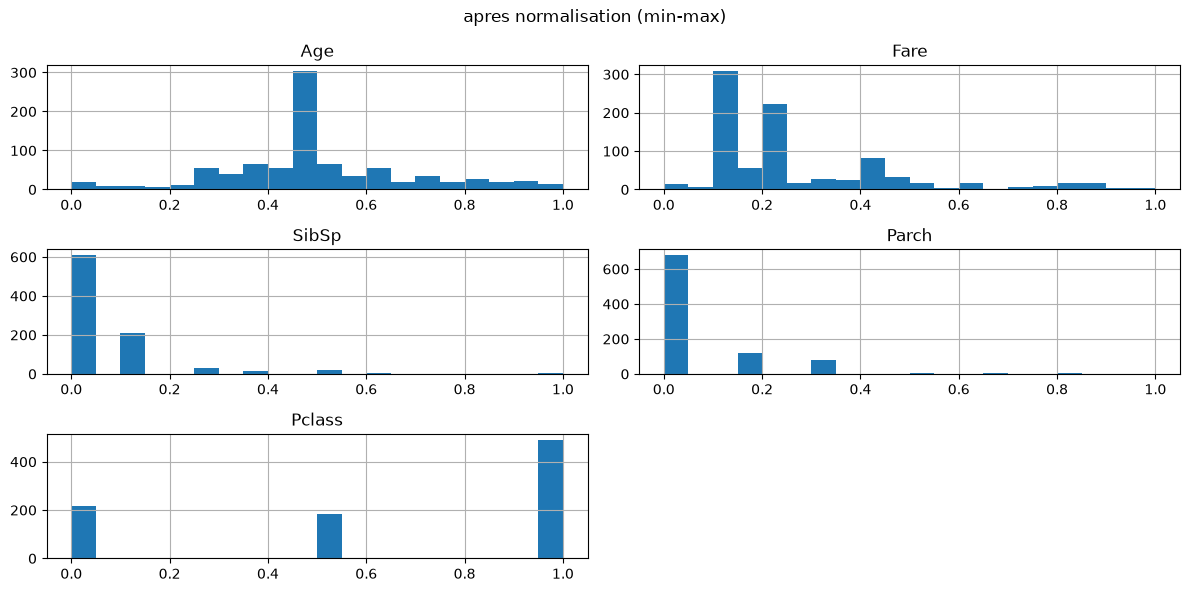

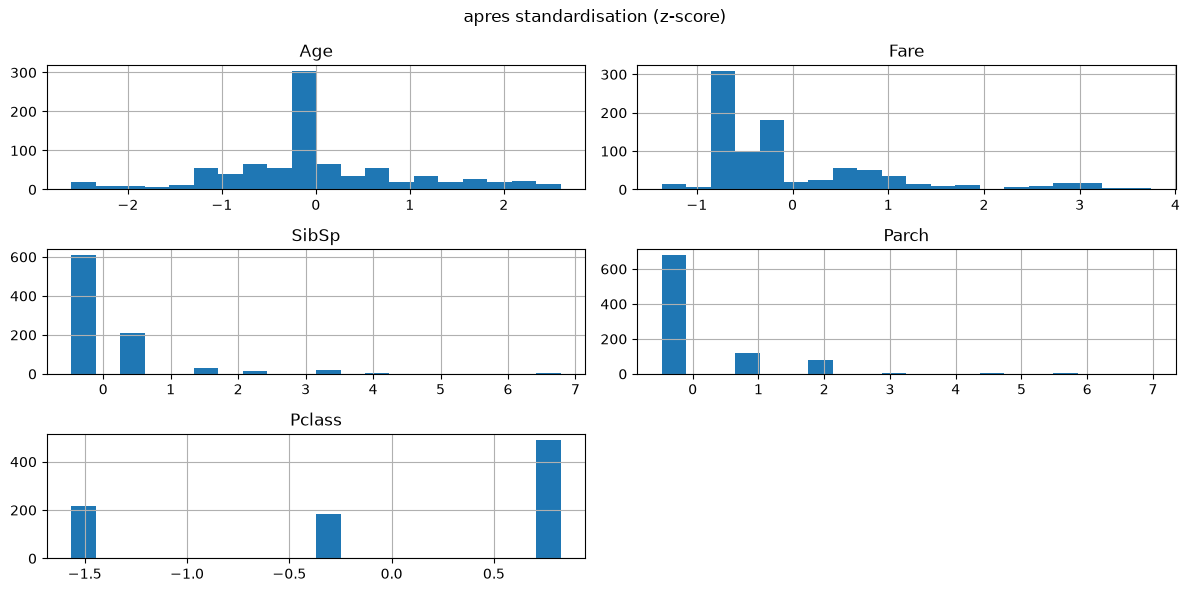

In [9]:
t[c].hist(figsize=(12, 6), bins=20)
plt.suptitle("Data original dyalna")
plt.tight_layout()
plt.show()


t_minmax[c].hist(figsize=(12, 6), bins=20)
plt.suptitle("apres normalisation (min-max)")
plt.tight_layout()
plt.show()


t_standard[c].hist(figsize=(12, 6), bins=20)
plt.suptitle("apres standardisation (z-score)")
plt.tight_layout()
plt.show()

PARTIE 4:

In [10]:
print(t["Survived"].value_counts())
print(t["Survived"].value_counts(normalize=True) * 100)

non_surv= t[t["Survived"] == 0]
surv = t[t["Survived"] == 1]
s= non_surv.sample(len(surv))
us = pd.concat([s, surv])
print(us["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64
Survived
0    342
1    342
Name: count, dtype: int64


In [11]:
from imblearn.over_sampling import SMOTE 

X = t.drop(columns=["Survived", "PassengerId", "Name", "Ticket"])
y=t["Survived"]

smote = SMOTE() 

X_smote, y_smote = smote.fit_resample(X, y)


print("avant SMOTE :")
display(y.value_counts())


print("apres SMOTE :")
display(y_smote.value_counts())


avant SMOTE :


Survived
0    549
1    342
Name: count, dtype: int64

apres SMOTE :


Survived
0    549
1    549
Name: count, dtype: int64